# Curve di capitale e metriche, train e test

**Cosa chiede il professore** ([resources/instructions.pdf](../resources/instructions.pdf), "The Evaluation Framework"): valutare la strategia con metriche adatte, **sia sul train sia sul test**, e confrontarla con un **benchmark** giustificandone la scelta. Tra le metriche: rendimento cumulato disegnato come **curva di capitale che parte da 100, con il benchmark sullo stesso grafico**, rendimento annualizzato, volatilità annualizzata, Sharpe (dichiarando il tasso privo di rischio), massimo drawdown, profit factor.

**Da dove vengono i rendimenti.** Dal segnale +1 / 0 / -1 per titolo di [08_segnale.ipynb](08_segnale.ipynb), con la formula del professore: rendimento del titolo x segnale. Sono i rendimenti giornalieri salvati in `Results/rendimenti_segnale.csv` (train) e `Results/test/rendimenti_segnale.csv` (test). Coincidono con quelli dei trade a meno dello 0,3%, ma Sharpe e drawdown qui possono differire di poco da quelli dei Passaggi 6 e 7, che sono calcolati dai trade. Questo notebook legge solo file salvati: non rifà il test.

**Le versioni.** **A** (nessun agente), **B** e **C** di `finbert_episodio`, quelle portate sul test.

**I benchmark e perché.**
- **SPY comprato e tenuto** (l'ETF sull'S&P 500): è il mercato azionario americano da cui vengono le 30 azioni, il confronto suggerito dal professore. Dice se la strategia rende più o meno della borsa e se ne dipende.
- **La versione A**: è la strategia senza agente. È il confronto giusto per dire se l'agente di notizie aiuta, che è la domanda del progetto.
- Non usiamo i 30 titoli comprati e tenuti: la strategia compra e vende insieme ed è quasi sempre fuori dal mercato, quindi quel confronto direbbe poco.

## Le ipotesi di calcolo

- **Capitale e curva della strategia.** 300.000 dollari (20.000 per coppia), senza reinvestimento, come nel backtest: il rendimento di un giorno è il guadagno del giorno diviso 300.000, e la curva è 100 x (1 + somma dei rendimenti giornalieri). I giorni senza posizioni valgono 0.
- **Curva di SPY.** Comprato al prezzo di chiusura del giorno prima dell'inizio e tenuto: 100 x prodotto di (1 + rendimento giornaliero). Prezzi aggiustati per i dividendi, da Alpaca.
- **Rendimento annualizzato**, uguale per tutti: (1 + rendimento cumulato) elevato a 252 / giorni, meno 1. Su 64 giorni (train) e 32 (test) è poco affidabile: riporta a un anno pochi mesi.
- **Volatilità annualizzata:** deviazione standard dei rendimenti giornalieri x radice di 252.
- **Sharpe:** media dei rendimenti giornalieri / deviazione standard x radice di 252, con **tasso privo di rischio 0**. Scelta: la strategia chiude tutto ogni sera e il capitale non è investito di notte; dichiarato qui e nel report.
- **Massimo drawdown:** la perdita più grande della curva da un suo massimo precedente, in percentuale.
- **Profit factor:** somma dei guadagni dei giorni positivi diviso la somma delle perdite dei giorni negativi (sui giorni, perché i rendimenti vengono dal segnale; quello per trade è nei Passaggi 6 e 7).
- **Costi:** 0 (principale, indicazione del docente) e 5 punti base per operazione per confronto. Un'operazione è ogni variazione di 1 del segnale di un titolo: aprire un trade sono 2 operazioni (due titoli), chiuderlo altre 2, quindi 4 per trade come nel backtest. Costo di un'operazione: 5 punti base di 10.000 dollari, cioè 5 dollari.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # cartella del progetto: rende importabile src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RESULTS, RESULTS_TEST, SPY_DAILY, SPY_TEST, VARIANTI
from src.backtest import DAYS_PER_YEAR, NOTIONAL_LEG
from src.varianti_agente.confronto import beta_alpha

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 220
CAPITALE = 300_000
PERIODI = ("train", "test")
rend = {"train": pd.read_csv(RESULTS / "rendimenti_segnale.csv", index_col="day", parse_dates=True),
        "test": pd.read_csv(RESULTS_TEST / "rendimenti_segnale.csv", index_col="day", parse_dates=True)}
segnali = {("train", "A"): RESULTS / "segnale_A.parquet", ("train", "B"): VARIANTI / "finbert_episodio/segnale_B.parquet",
           ("train", "C"): VARIANTI / "finbert_episodio/segnale_C.parquet"} | {("test", v): RESULTS_TEST / f"segnale_{v}.parquet" for v in "ABC"}
spy = {"train": pd.read_parquet(SPY_DAILY), "test": pd.read_parquet(SPY_TEST)}
for per in PERIODI:
    close = spy[per].set_index("date").close
    rend[per]["SPY"] = close.pct_change().reindex(rend[per].index)    # il primo giorno usa la chiusura del giorno prima
    assert rend[per].notna().all().all(), f"manca SPY in qualche giorno del {per}"
    print(f"{per}: {len(rend[per])} giorni, dal {rend[per].index.min():%d/%m/%Y} al {rend[per].index.max():%d/%m/%Y}")

train: 64 giorni, dal 16/06/2026 al 16/09/2026
test: 32 giorni, dal 17/09/2026 al 30/10/2026


## 1. I costi dal segnale

Per lo scenario a 5 punti base: per ogni giorno si contano le operazioni, cioè le variazioni del segnale di ogni titolo, compresa la chiusura a fine giornata. Il controllo: le operazioni sono esattamente 4 per trade.

In [2]:
def operazioni_per_giorno(s: pd.DataFrame) -> pd.Series:
    """Numero di operazioni (variazioni di 1 del segnale di un titolo) per giorno. Ogni giornata parte da 0 e finisce a 0."""
    def un_giorno(x):
        return x.diff().fillna(x).abs().to_numpy().sum() + x.iloc[-1].abs().sum()
    return s.groupby(s.index.normalize()).apply(un_giorno)


oper = {}
for (per, v), path in segnali.items():
    oper[(per, v)] = operazioni_per_giorno(pd.read_parquet(path)).reindex(rend[per].index, fill_value=0)
pd.DataFrame({"operazioni": {k: int(o.sum()) for k, o in oper.items()}, "trade": {k: o.sum() / 4 for k, o in oper.items()}}).rename_axis(["periodo", "versione"])

operazioni  trade
periodo versione                   
train   A               3892 973.00
        B               3872 968.00
        C               3876 969.00
test    A               2000 500.00
        B               1972 493.00
        C               1980 495.00

## 2. Curve di capitale da 100

A, B e C (costo 0) e SPY sullo stesso grafico, per il train e per il test. Tutte le curve valgono 100 alla chiusura del giorno di borsa prima del periodo (15 giugno per il train, 16 settembre per il test).

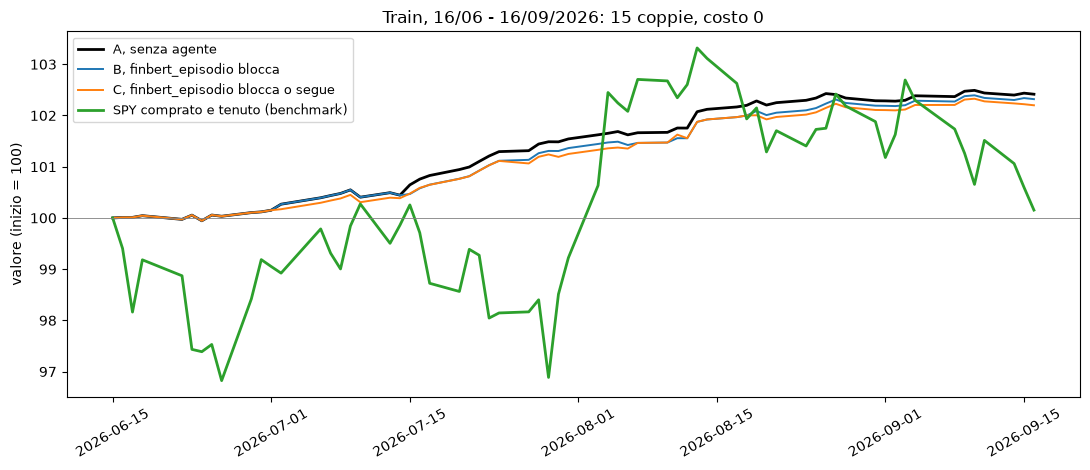

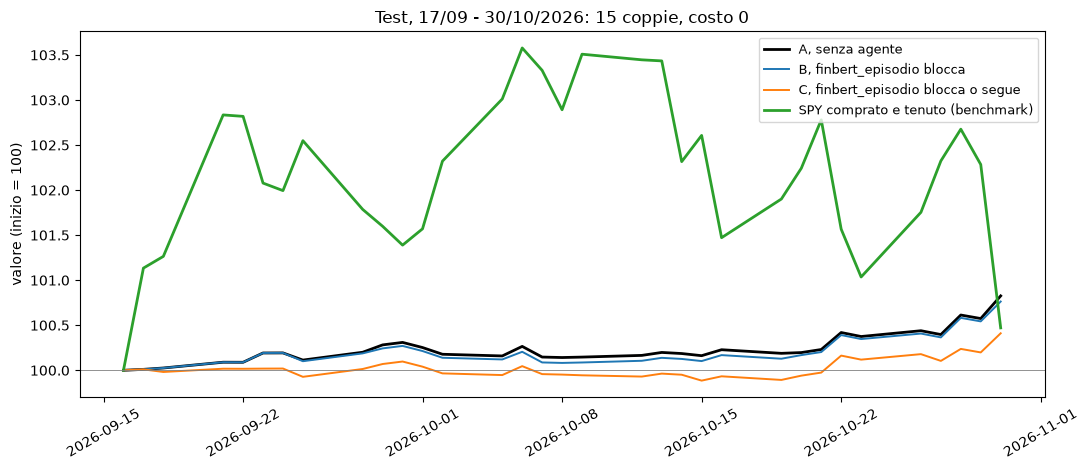

In [3]:
INIZIO = {per: spy[per].date[spy[per].date < rend[per].index.min()].max() for per in PERIODI}   # giorno di borsa prima del periodo: la curva vale 100


def curva(r: pd.Series, nome: str, per: str) -> pd.Series:
    """Curva da 100 alla chiusura del giorno prima del periodo: la strategia somma i rendimenti (capitale fisso), SPY li capitalizza."""
    eq = 100 * (1 + r).cumprod() if nome == "SPY" else 100 * (1 + r.cumsum())
    return pd.concat([pd.Series([100.0], index=[INIZIO[per]]), eq])


STILE = {"A": ("black", "A, senza agente"), "B": ("tab:blue", "B, finbert_episodio blocca"),
         "C": ("tab:orange", "C, finbert_episodio blocca o segue"), "SPY": ("tab:green", "SPY comprato e tenuto (benchmark)")}
for per, path in (("train", RESULTS / "curva_capitale_100.png"), ("test", RESULTS_TEST / "curva_capitale_100.png")):
    fig, ax = plt.subplots(figsize=(11, 4.8))
    for nome, (colore, etichetta) in STILE.items():
        ax.plot(curva(rend[per][nome], nome, per), color=colore, lw=2 if nome in ("A", "SPY") else 1.4, label=etichetta)
    ax.axhline(100, color="grey", lw=0.6)
    ax.set_ylabel("valore (inizio = 100)")
    ax.set_title(f"{per.capitalize()}, {rend[per].index.min():%d/%m} - {rend[per].index.max():%d/%m/%Y}: 15 coppie, costo 0")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=9)
    fig.tight_layout()
    fig.savefig(path, dpi=120)
    plt.show()

## 3. Metriche, train e test

Una riga per periodo, costo e versione; SPY non ha costi. `trade` è il numero di trade (operazioni / 4).

In [4]:
def metriche(r: pd.Series, nome: str, per: str) -> dict:
    eq = curva(r, nome, per)
    cum = eq.iloc[-1] / 100 - 1
    return dict(rendimento_cumulato_pct=100 * cum,
                rendimento_annuo_pct=100 * ((1 + cum) ** (DAYS_PER_YEAR / len(r)) - 1),
                volatilita_annua_pct=100 * r.std() * np.sqrt(DAYS_PER_YEAR),
                sharpe=r.mean() / r.std() * np.sqrt(DAYS_PER_YEAR),
                max_drawdown_pct=100 * (eq / eq.cummax() - 1).min(),
                profit_factor=r[r > 0].sum() / -r[r < 0].sum())


righe = []
for per in PERIODI:
    for costo in (0, 5):
        for v in "ABC":
            r = rend[per][v] - oper[(per, v)] * costo / 1e4 * NOTIONAL_LEG / CAPITALE
            righe.append(dict(periodo=per, costo_bps=costo, versione=v, trade=int(oper[(per, v)].sum() / 4)) | metriche(r, v, per))
    righe.append(dict(periodo=per, costo_bps=0, versione="SPY", trade=np.nan) | metriche(rend[per]["SPY"], "SPY", per))
tabella = pd.DataFrame(righe).set_index(["periodo", "costo_bps", "versione"])
tabella

trade  rendimento_cumulato_pct  rendimento_annuo_pct  volatilita_annua_pct  sharpe  max_drawdown_pct  profit_factor
periodo costo_bps versione                                                                                                                     
train   0         A        973.00                     2.42                  9.85                  1.17    8.16             -0.14           3.94
                  B        968.00                     2.32                  9.45                  1.12    8.17             -0.14           3.89
                  C        969.00                     2.20                  8.94                  1.16    7.49             -0.14           3.49
        5         A        973.00                    -4.07                -15.10                  1.18  -13.58             -4.07           0.10
                  B        968.00                    -4.13                -15.32                  1.11  -14.67             -4.13           0.07
                  C        969.00                    -4.26                -15.76                  1.13  -14.88             -4.26           0.08
        0         SPY         NaN                     0.15                  0.60                 11.69    0.11             -3.38           1.02
test    0         A        500.00                     0.83                  6.69                  1.32    4.93             -0.17           2.49
                  B        493.00                     0.76                  6.17                  1.27    4.74             -0.19           2.34
                  C        495.00                     0.41                  3.28                  1.17    2.77             -0.21           1.62
        5         A        500.00                    -2.51                -18.13                  1.29  -15.28             -2.65           0.11
                  B        493.00                    -2.52                -18.23                  1.25  -15.88             -2.64           0.10
                  C        495.00                    -2.89                -20.62                  1.15  -19.82             -3.00           0.06
        0         SPY         NaN                     0.47                  3.77                 11.41    0.38             -3.00           1.06

## 4. La strategia dipende dal mercato?

Per il punto bonus "market-neutral" il professore guarda, sul test: beta rispetto all'S&P 500 vicino a zero, bassa correlazione con l'indice e rendimento medio positivo nei giorni in cui l'indice scende. Qui per A, B e C (costo 0), su train e test. Il beta viene dalla regressione dei rendimenti giornalieri su quelli di SPY.

In [5]:
righe = []
for per in PERIODI:
    spy_r = rend[per]["SPY"]
    giu = spy_r < 0
    for v in "ABC":
        r = rend[per][v]
        ba = beta_alpha(r, spy_r)
        righe.append(dict(periodo=per, versione=v, beta=ba["beta"], t_beta=ba["t_beta"], correlazione=r.corr(spy_r),
                          giorni_spy_giu=int(giu.sum()), rend_medio_giorni_spy_giu_bps=1e4 * r[giu].mean(),
                          quota_positivi_giorni_spy_giu=(r[giu] > 0).mean(), rend_medio_spy_giu_bps=1e4 * spy_r[giu].mean()))
neutralita = pd.DataFrame(righe).set_index(["periodo", "versione"])
neutralita

beta  t_beta  correlazione  giorni_spy_giu  rend_medio_giorni_spy_giu_bps  quota_positivi_giorni_spy_giu  rend_medio_spy_giu_bps
periodo versione                                                                                                                                  
train   A         0.01    0.59          0.08              36                           2.69                           0.69                  -51.47
        B         0.01    0.62          0.08              36                           2.63                           0.69                  -51.47
        C         0.01    0.54          0.07              36                           2.55                           0.69                  -51.47
test    A        -0.04   -2.20         -0.37              16                           3.99                           0.62                  -54.58
        B        -0.04   -2.10         -0.36              16                           3.63                           0.62                  -54.58
        C        -0.04   -2.30         -0.39              16                           2.81                           0.56                  -54.58

## 5. Salvataggio

`Results/metriche_train_test.csv`, `Results/neutralita_mercato.csv` e i due grafici (`Results/curva_capitale_100.png`, `Results/test/curva_capitale_100.png`).

In [6]:
tabella.to_csv(RESULTS / "metriche_train_test.csv")
neutralita.to_csv(RESULTS / "neutralita_mercato.csv")
for p in (RESULTS / "metriche_train_test.csv", RESULTS / "neutralita_mercato.csv", RESULTS / "curva_capitale_100.png", RESULTS_TEST / "curva_capitale_100.png"):
    print(p.relative_to(RESULTS.parent), p.exists())

Results/metriche_train_test.csv True
Results/neutralita_mercato.csv True
Results/curva_capitale_100.png True
Results/test/curva_capitale_100.png True


## 6. Cosa ci dicono i risultati

Rendimenti dal segnale, costo 0 salvo dove è detto. A senza agente, B e C con `finbert_episodio`.

| | A | B | C | SPY |
|---|---|---|---|---|
| **Train:** rendimento cumulato | +2,42% | +2,32% | +2,20% | +0,15% |
| rendimento annualizzato | +9,9% | +9,5% | +8,9% | +0,6% |
| volatilità annualizzata | 1,2% | 1,1% | 1,2% | 11,7% |
| Sharpe (tasso privo di rischio 0) | 8,2 | 8,2 | 7,5 | 0,1 |
| massimo drawdown | -0,14% | -0,14% | -0,14% | -3,4% |
| profit factor (sui giorni) | 3,9 | 3,9 | 3,5 | 1,0 |
| **Test:** rendimento cumulato | +0,83% | +0,76% | +0,41% | +0,47% |
| rendimento annualizzato | +6,7% | +6,2% | +3,3% | +3,8% |
| volatilità annualizzata | 1,3% | 1,3% | 1,2% | 11,4% |
| Sharpe (tasso privo di rischio 0) | 4,9 | 4,7 | 2,8 | 0,4 |
| massimo drawdown | -0,17% | -0,19% | -0,21% | -3,0% |
| profit factor (sui giorni) | 2,5 | 2,3 | 1,6 | 1,1 |

**L'agente non migliora la strategia, nemmeno con queste metriche.** In tutti e due i periodi la B sta poco sotto la A e la C più sotto, su ogni metrica tranne la volatilità, che è uguale per tutte. Sono gli stessi risultati dei Passaggi 6 e 7, visti come curva di capitale.
- **B** è quasi uguale alla A: sul test blocca solo 7 trade su 500. Rendimento +0,76% contro +0,83%, Sharpe 4,7 contro 4,9.
- **C** è la peggiore. Sul test rende +0,41%, meno anche di SPY (+0,47%), anche se con molto meno rischio; Sharpe 2,8, drawdown -0,21%.

**Contro SPY, a costo 0, tutte e tre le versioni hanno molto meno rischio**: volatilità 1,1-1,3% l'anno contro 11-12%, drawdown sotto lo 0,25% contro il 3%. Sul rendimento A e B fanno meglio di SPY in tutti e due i periodi; la C sul train sì, sul test no.

**Da leggere con cautela.**
- La volatilità è bassissima perché il capitale è investito solo durante il giorno, in pochi trade alla volta, e mai di notte. Per questo lo Sharpe è molto alto: non va confrontato con quello di un fondo.
- Le cifre annualizzate riportano a un anno 64 giorni (train) e 32 (test). In questi periodi SPY è quasi fermo: +0,15% sul train e +0,47% sul test.
- **Con 5 punti base di costo tutte le versioni perdono:** sul test A -2,5%, B -2,5%, C -2,9%; sul train A -4,1%, B -4,1%, C -4,3%. Il guadagno lordo per trade è più piccolo di un costo realistico. Il costo 0 è l'indicazione del docente.

**Coerenza con i notebook 06 e 07.** Dal segnale lo Sharpe della A sul test è 4,93; dai trade era 4,92. Il drawdown a costo 5 coincide (-2,65% sul test, -4,07% sul train).

**Dipendenza dal mercato** (sezione 4, punto bonus "market-neutral"), sul test:

| | A | B | C |
|---|---|---|---|
| beta rispetto a SPY (statistica t) | -0,04 (-2,2) | -0,04 (-2,1) | -0,04 (-2,3) |
| correlazione con SPY | -0,37 | -0,36 | -0,39 |
| guadagno medio nei 16 giorni in cui SPY scende | +4,0 bps | +3,6 bps | +2,8 bps |
| quota di quei giorni in positivo | 62% | 62% | 56% |

- **Beta vicino a zero** per tutte e tre, sul train (0,01) e sul test (-0,04).
- **Nei giorni in cui SPY scende** (sul test -55 punti base in media) tutte e tre guadagnano in media, la C meno delle altre. Sul train: +2,7 bps per la A, +2,6 per la B, +2,6 per la C, positive nel 69% dei giorni.
- **Correlazione con SPY:** bassa sul train (0,07-0,08), più marcata e negativa sul test (da -0,36 a -0,39). Sul test il beta, pur piccolo, è distinguibile da zero: la strategia tende a guadagnare un po' di più quando la borsa scende.
- **Rendimenti piccoli in assoluto:** meno dell'1% in sei settimane. Il professore chiede rendimenti "rilevanti e costanti"; va valutato se questo lo sono.

**Limiti.**
- Train e test sono brevi e in entrambi SPY si muove poco: un solo tipo di mercato.
- Tasso privo di rischio 0: con il rendimento dei titoli di Stato lo Sharpe sarebbe più basso.
- Non c'è un test statistico sulla differenza di Sharpe tra strategia e SPY.